# Exploratory Data Analysis — Heart Disease Dataset

This notebook performs a complete exploratory data analysis (EDA) of the heart disease dataset (303 patient records, 14 columns)

**What this notebook covers:**
1. Dataset overview & column-by-column description
2. Missing value detection & handling
3. Non-numeric character detection in numeric columns
4. Duplicate detection & handling
5. Suspicious / invalid value detection (out-of-codebook values)
6. Outlier detection & handling
7. A variety of visualizations exploring distributions, relationships, and patterns relevant to heart disease


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10.5
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

df = pd.read_csv('/kaggle/input/datasets/ssaeedhm/heart-disease-dataset/heart.csv')
print(f"Shape: {df.shape}")
df.head()


Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## 1. Dataset Overview & Column Descriptions

The table below summarizes every column:

| Column | Description |
|---|---|
| `age` | Age of the patient in years |
| `sex` | Gender of the patient (0 = male, 1 = female, per codebook) |
| `cp` | Chest pain type: 0 = typical angina, 1 = atypical angina, 2 = non-anginal pain, 3 = asymptomatic |
| `trestbps` | Resting blood pressure (mm Hg) |
| `chol` | Serum cholesterol (mg/dl) |
| `fbs` | Fasting blood sugar > 120 mg/dl (1 = true, 0 = false) |
| `restecg` | Resting ECG results: 0 = normal, 1 = ST-T wave abnormality, 2 = probable/definite left ventricular hypertrophy |
| `thalach` | Maximum heart rate achieved during stress test |
| `exang` | Exercise-induced angina (1 = yes, 0 = no) |
| `oldpeak` | ST depression induced by exercise relative to rest |
| `slope` | Slope of the peak exercise ST segment: 0 = upsloping, 1 = flat, 2 = downsloping |
| `ca` | Number of major vessels (0–4) colored by fluoroscopy |
| `thal` | Thalium stress test result: 0 = normal, 1 = fixed defect, 2 = reversible defect, 3 = not described |
| `target` | Heart disease status (0 = no disease, 1 = presence of disease) |


We also split columns conceptually into:
- **Continuous/numeric:** `age`, `trestbps`, `chol`, `thalach`, `oldpeak`
- **Categorical (encoded as integers):** `sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, `thal`, `target`


In [2]:
continuous_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target']

print("Data types:")
print(df.dtypes)
print()
df.describe().T


Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object



,count,mean,std,min,25%,50%,75%,max
age,303.0,54.366337,9.082101,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.683168,0.466011,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.966997,1.032052,0.0,0.0,1.0,2.0,3.0
trestbps,303.0,131.623762,17.538143,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.264026,51.830751,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.528053,0.525860,0.0,0.0,1.0,1.0,2.0
thalach,303.0,149.646865,22.905161,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## 2. Missing Value Detection & Handling

We check for:
- Standard missing values (`NaN` / `None`, as pandas detects them on load)
- "Hidden" missing values disguised as placeholder strings (e.g. `"?"`, `"-"`, `"NA"`, empty strings) — common in datasets exported from clinical tools


In [3]:
# Standard NaNs
print("Missing values per column (standard NaN check):")
print(df.isna().sum())
print(f"\nTotal missing cells: {df.isna().sum().sum()}")

# Hidden missing values disguised as strings (re-read as raw strings to check)
df_raw = pd.read_csv('/kaggle/input/datasets/ssaeedhm/heart-disease-dataset/heart.csv', dtype=str)
placeholder_tokens = ['?', '-', 'na', 'n/a', 'none', 'null', '']
hidden_missing = {}
for col in df_raw.columns:
    mask = df_raw[col].astype(str).str.strip().str.lower().isin(placeholder_tokens)
    if mask.sum() > 0:
        hidden_missing[col] = mask.sum()

print(f"\nHidden missing values disguised as placeholder strings: {hidden_missing if hidden_missing else 'None found'}")


Missing values per column (standard NaN check):
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total missing cells: 0

Hidden missing values disguised as placeholder strings: None found


**Result:** the dataset has **no missing values** — neither standard `NaN`s nor disguised placeholder strings. No imputation is required.

*(For completeness, if missing values had been found, the standard handling strategy would be: drop rows/columns with excessive missingness, and impute the rest — median for skewed continuous variables like `chol`/`oldpeak`, mean for roughly symmetric ones like `trestbps`, and mode for categorical variables like `thal`/`slope`.)*


## 3. Non-Numeric Character Detection in Numeric Columns

All 14 columns are expected to be purely numeric (integers or floats). We verify this by checking the **raw string values** with a regex, rather than trusting `pandas`' automatic type inference (which can silently coerce or mask issues).


In [4]:
import re

numeric_pattern = re.compile(r'^-?\d+(\.\d+)?$')

non_numeric_report = {}
for col in df_raw.columns:
    bad_values = df_raw[col][~df_raw[col].astype(str).str.strip().apply(lambda x: bool(numeric_pattern.match(x)))]
    if len(bad_values) > 0:
        non_numeric_report[col] = bad_values.unique().tolist()

if non_numeric_report:
    print("Columns with non-numeric characters found:")
    for col, vals in non_numeric_report.items():
        print(f"  {col}: {vals}")
else:
    print("No non-numeric characters found in any column — all values are clean numeric strings.")


No non-numeric characters found in any column — all values are clean numeric strings.


**Result:** every cell in every column matches a strict numeric pattern (digits, optional decimal point, optional leading minus). No stray text, units, or symbols are present.

## 4. Duplicate Rows

Exact duplicate rows can bias statistics and inflate model performance if not removed before train/test splitting.


In [5]:
n_dupes = df.duplicated().sum()
print(f"Number of exact duplicate rows: {n_dupes}")
if n_dupes > 0:
    display(df[df.duplicated(keep=False)])

df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"\nShape before: {df.shape}  ->  Shape after removing duplicates: {df_clean.shape}")


Number of exact duplicate rows: 1


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
163,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1



Shape before: (303, 14)  ->  Shape after removing duplicates: (302, 14)


**Handling:** the single duplicate row is dropped. From this point on, `df_clean` (302 rows) is used for the outlier, suspicious-value, and visualization sections.

## 5. Suspicious / Invalid Value Detection

Categorical columns should only take values within the ranges defined by the codebook. We scan every categorical column for out-of-range values.


In [6]:
expected_ranges = {
    'sex': [0, 1],
    'cp': [0, 1, 2, 3],
    'fbs': [0, 1],
    'restecg': [0, 1, 2],
    'exang': [0, 1],
    'slope': [0, 1, 2],
    'ca': [0, 1, 2, 3],       # codebook says 0-4, but 4 is a known invalid/missing marker in this dataset
    'thal': [1, 2, 3],        # codebook lists 1,2,3 as valid categories; 0 is not a defined category
    'target': [0, 1],
}

print("Out-of-codebook value check:")
for col, valid_vals in expected_ranges.items():
    actual_vals = sorted(df_clean[col].unique())
    invalid = [v for v in actual_vals if v not in valid_vals]
    if invalid:
        count = df_clean[col].isin(invalid).sum()
        print(f"  ⚠️  {col}: found values {invalid} not in expected {valid_vals}  ({count} rows)")
    else:
        print(f"  ✅ {col}: all values within {valid_vals}")


Out-of-codebook value check:
  ✅ sex: all values within [0, 1]
  ✅ cp: all values within [0, 1, 2, 3]
  ✅ fbs: all values within [0, 1]
  ✅ restecg: all values within [0, 1, 2]
  ✅ exang: all values within [0, 1]
  ✅ slope: all values within [0, 1, 2]
  ⚠️  ca: found values [np.int64(4)] not in expected [0, 1, 2, 3]  (4 rows)
  ⚠️  thal: found values [np.int64(0)] not in expected [1, 2, 3]  (2 rows)
  ✅ target: all values within [0, 1]


**Findings:**
- **`ca` = 4** appears in 4 rows (5 before duplicate removal). The PDF lists a 0–4 range, but the original UCI Heart Disease data this file derives from only contains 0–3, so `4` is widely treated as a data-entry artifact / missing-value code.
- **`thal` = 0** appears in 2 rows. The PDF lists `0` as "Normal", but the original UCI data has no such category, and with only 2 rows it is commonly treated as a missing-value code.

These are *suspicions based on the dataset's origin*, not proof of error, and importantly they are judged from the columns' own value ranges, **never from the `target`**.

**Handling strategy:** rather than deleting these rows (and losing other valid information in them), we flag them and treat `ca=4` / `thal=0` as **missing-value codes**. For downstream modeling they would typically be imputed with the column mode; for this EDA, we keep them visible but call them out explicitly in the relevant plots below.


In [7]:
suspicious_mask = (df_clean['ca'] == 4) | (df_clean['thal'] == 0)
print(f"Rows flagged as containing a suspicious/invalid categorical code: {suspicious_mask.sum()} out of {len(df_clean)}")
df_clean['suspicious_flag'] = suspicious_mask
df_clean[suspicious_mask][['age','sex','ca','thal','target']]


Rows flagged as containing a suspicious/invalid categorical code: 6 out of 302


,age,sex,ca,thal,target
48,53,0,0,0,1
92,52,1,4,2,1
158,58,1,4,3,1
163,38,1,4,2,1
250,43,1,4,3,0
280,52,1,0,0,0


## 6. Outlier Detection & Handling

We apply the **IQR (Interquartile Range) method** to the five continuous variables: `age`, `trestbps`, `chol`, `thalach`, `oldpeak`. A value is flagged as an outlier if it falls outside `[Q1 − 1.5×IQR, Q3 + 1.5×IQR]`.


In [8]:
def iqr_outliers(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    return mask, lower, upper

outlier_summary = []
for col in continuous_cols:
    mask, lower, upper = iqr_outliers(df_clean[col])
    outlier_summary.append({
        'column': col, 'n_outliers': mask.sum(),
        'pct': round(100 * mask.sum() / len(df_clean), 1),
        'lower_bound': round(lower, 2), 'upper_bound': round(upper, 2),
        'min': df_clean[col].min(), 'max': df_clean[col].max()
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df


,column,n_outliers,pct,lower_bound,upper_bound,min,max
0,age,0,0.0,28.50,80.50,29.0,77.0
1,trestbps,9,3.0,90.00,170.00,94.0,200.0
2,chol,5,1.7,115.38,370.38,126.0,564.0
3,thalach,1,0.3,84.12,215.12,71.0,202.0
4,oldpeak,5,1.7,-2.40,4.00,0.0,6.2


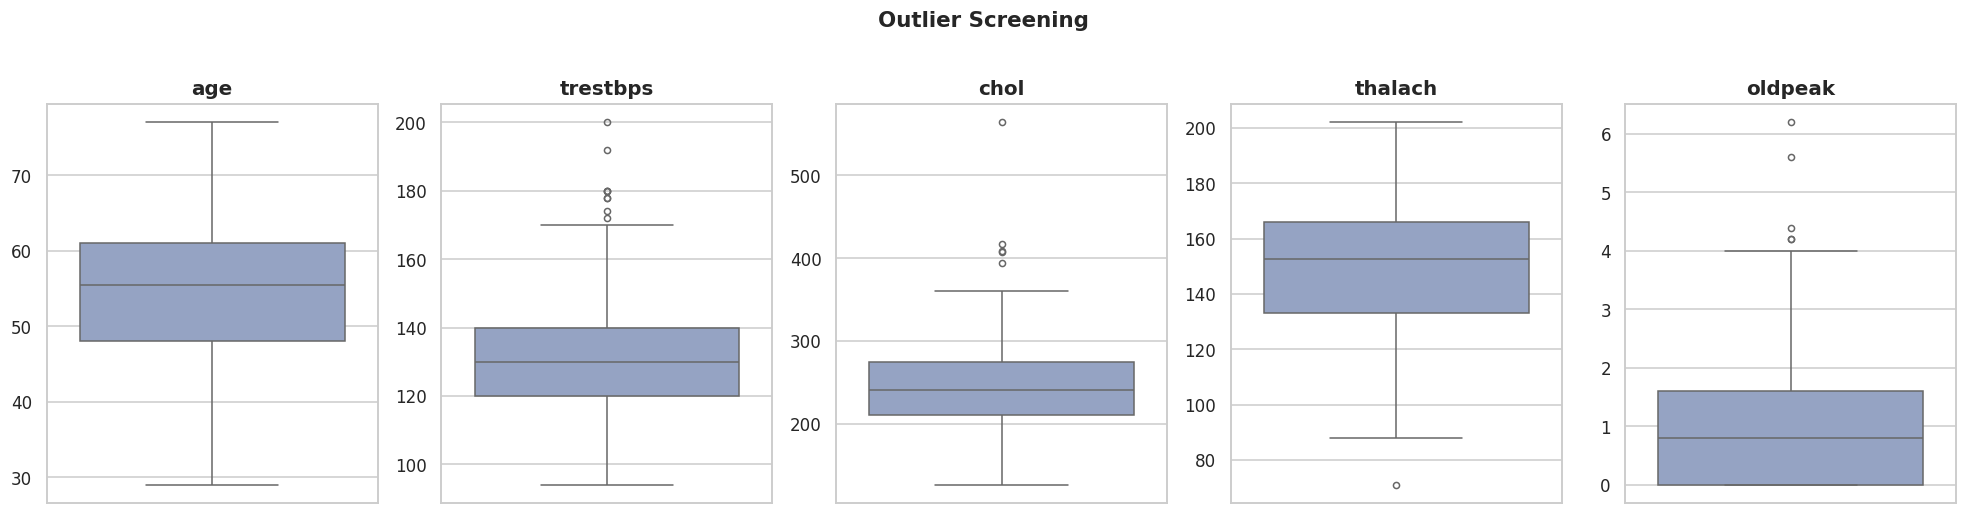

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4.5))
for ax, col in zip(axes, continuous_cols):
    sns.boxplot(y=df_clean[col], ax=ax, color=sns.color_palette("Set2")[2], fliersize=4)
    ax.set_title(col)
    ax.set_ylabel('')
fig.suptitle('Outlier Screening', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


**Findings & handling:**
- `trestbps` and `chol` show a moderate number of high-end outliers — clinically these correspond to patients with hypertension or very high cholesterol, which are **medically plausible**, not data errors.
- `oldpeak` and `thalach` show a few extreme points, also physiologically plausible (a very low max heart rate, or strong ST depression, can genuinely occur in diseased patients).
- `ca` (though categorical, technically discrete 0–4) has `4` already flagged as a data-quality issue in Section 5.

**Decision:** given the small dataset size (302 rows) and the clinical plausibility of these extreme-but-real values, we do **not remove** outliers — doing so would discard genuine high-risk patients and bias the disease-detection signal. Instead we **cap extreme values at the 1st/99th percentile only for visualization purposes** in a couple of plots below, and keep the raw values for anything analytical.


In [10]:
def winsorize(series, lower_pct=0.01, upper_pct=0.99):
    lower, upper = series.quantile(lower_pct), series.quantile(upper_pct)
    return series.clip(lower, upper)

df_viz = df_clean.copy()
for col in continuous_cols:
    df_viz[col + '_capped'] = winsorize(df_viz[col])

print("Capping applied (for visualization only) — example, chol:")
print(f"  original max: {df_clean['chol'].max()}, capped max: {df_viz['chol_capped'].max()}")


Capping applied (for visualization only) — example, chol:
  original max: 564, capped max: 406.8700000000001


## 7. Visualizations

A varied set of plots exploring distributions, relationships between variables, and patterns associated with heart disease (`target`).


### 7.1 Target Distribution — Class Balance

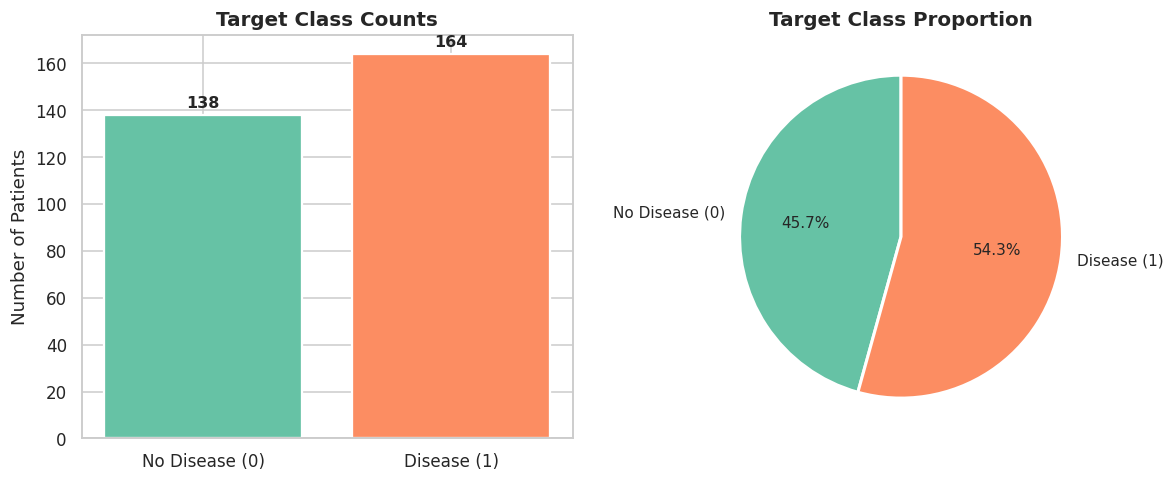

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

target_counts = df_clean['target'].value_counts().sort_index()
labels = ['No Disease (0)', 'Disease (1)']
colors = sns.color_palette("Set2")[:2]

axes[0].bar(labels, target_counts.values, color=colors, edgecolor='white', linewidth=1.5)
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 3, str(v), ha='center', fontweight='bold')
axes[0].set_title('Target Class Counts')
axes[0].set_ylabel('Number of Patients')

axes[1].pie(target_counts.values, labels=labels, autopct='%1.1f%%', colors=colors,
            startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2},
            textprops={'fontsize': 10})
axes[1].set_title('Target Class Proportion')

plt.tight_layout()
plt.show()


The dataset is reasonably **balanced** between the two classes, which is favorable for later modeling — no heavy resampling needed.

### 7.2 Age Distribution

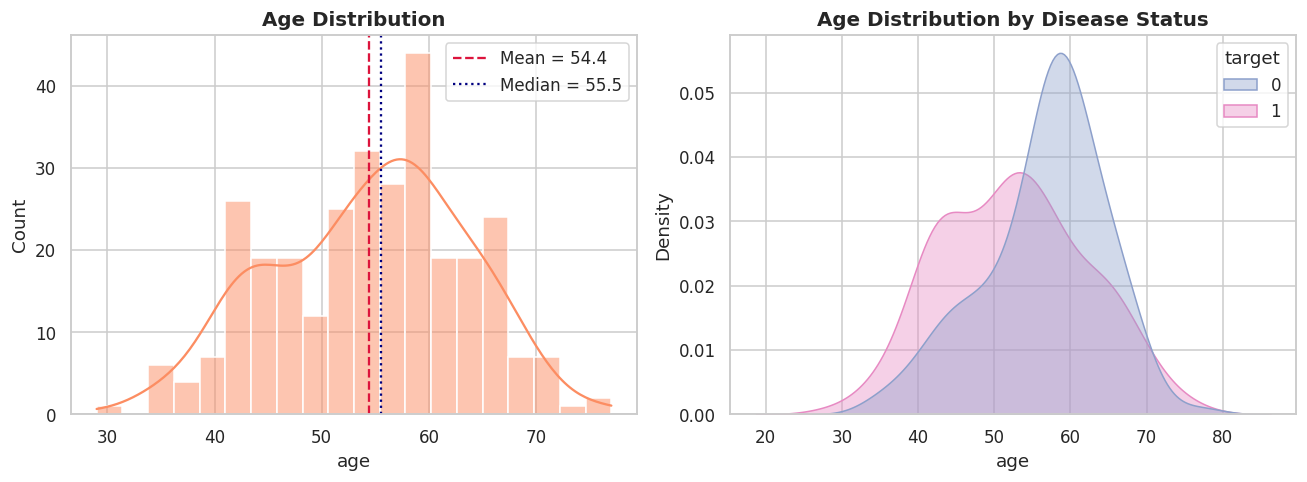

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(df_clean['age'], bins=20, kde=True, ax=axes[0], color=sns.color_palette("Set2")[1])
axes[0].axvline(df_clean['age'].mean(), color='crimson', linestyle='--', label=f"Mean = {df_clean['age'].mean():.1f}")
axes[0].axvline(df_clean['age'].median(), color='navy', linestyle=':', label=f"Median = {df_clean['age'].median():.1f}")
axes[0].set_title('Age Distribution')
axes[0].legend()

sns.kdeplot(data=df_clean, x='age', hue='target', fill=True, common_norm=False, alpha=0.4,
            palette={0: sns.color_palette("Set2")[2], 1: sns.color_palette("Set2")[3]}, ax=axes[1])
axes[1].set_title('Age Distribution by Disease Status')

plt.tight_layout()
plt.show()


Age is roughly bell-shaped, centered around the early-to-mid 50s. Splitting by `target` shows disease presence shifted slightly across the age range, though the overlap is substantial — age alone isn't a strong separator.

### 7.3 Correlation Heatmap

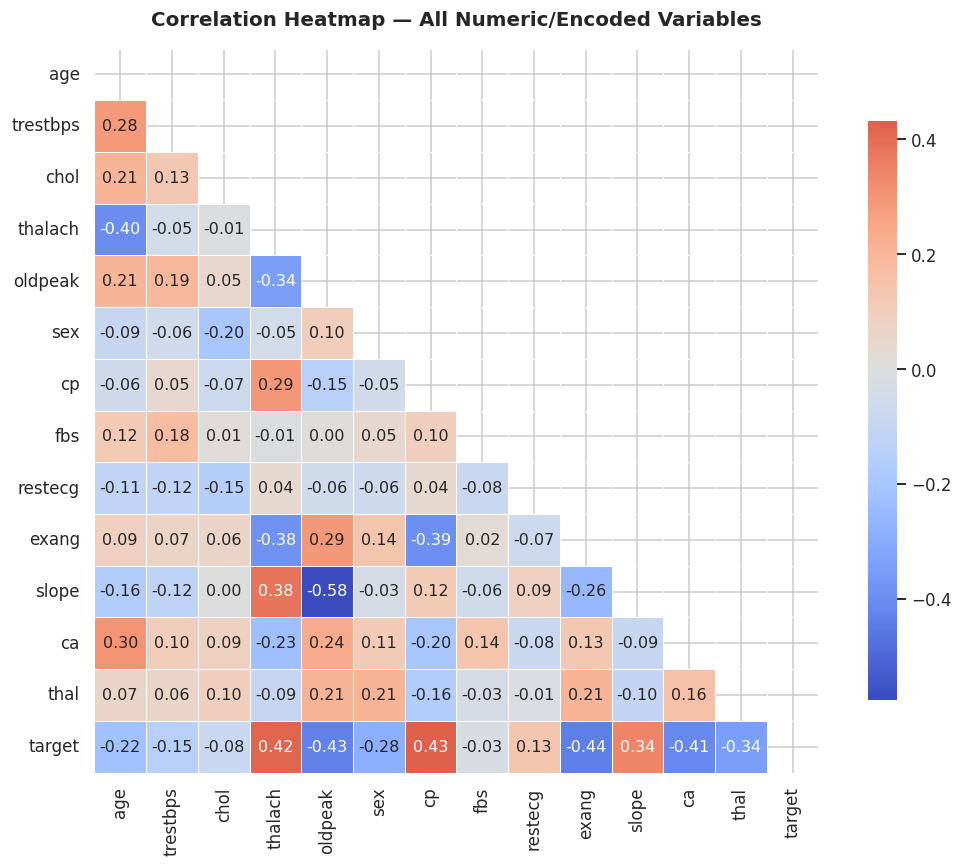

In [13]:
fig, ax = plt.subplots(figsize=(10, 8))
corr = df_clean[continuous_cols + categorical_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Correlation Heatmap — All Numeric/Encoded Variables', pad=15)
plt.tight_layout()
plt.show()


`cp`, `thalach`, and `slope` have the strongest **positive** correlation with `target`, while `exang`, `oldpeak`, `ca`, and `thal` have the strongest **negative** correlation.

> ⚠️ **Caution on the target coding.** Clinically, exercise-induced angina, higher ST depression, and more blocked vessels are all signs of *more* heart disease, yet here they go with a *lower* `target`. Likewise `thalach` (max heart rate) is higher where `target = 1`. Taken together this suggests that `target = 1` may actually mean *less* disease than the PDF states (inverted coding has been reported for this version of the dataset). The patterns below are therefore described exactly as they appear in the data ("target = 1" / "target = 0"); confirm the coding against the original source before drawing clinical conclusions.

### 7.4 Continuous Variables vs. Target — Violin Plots

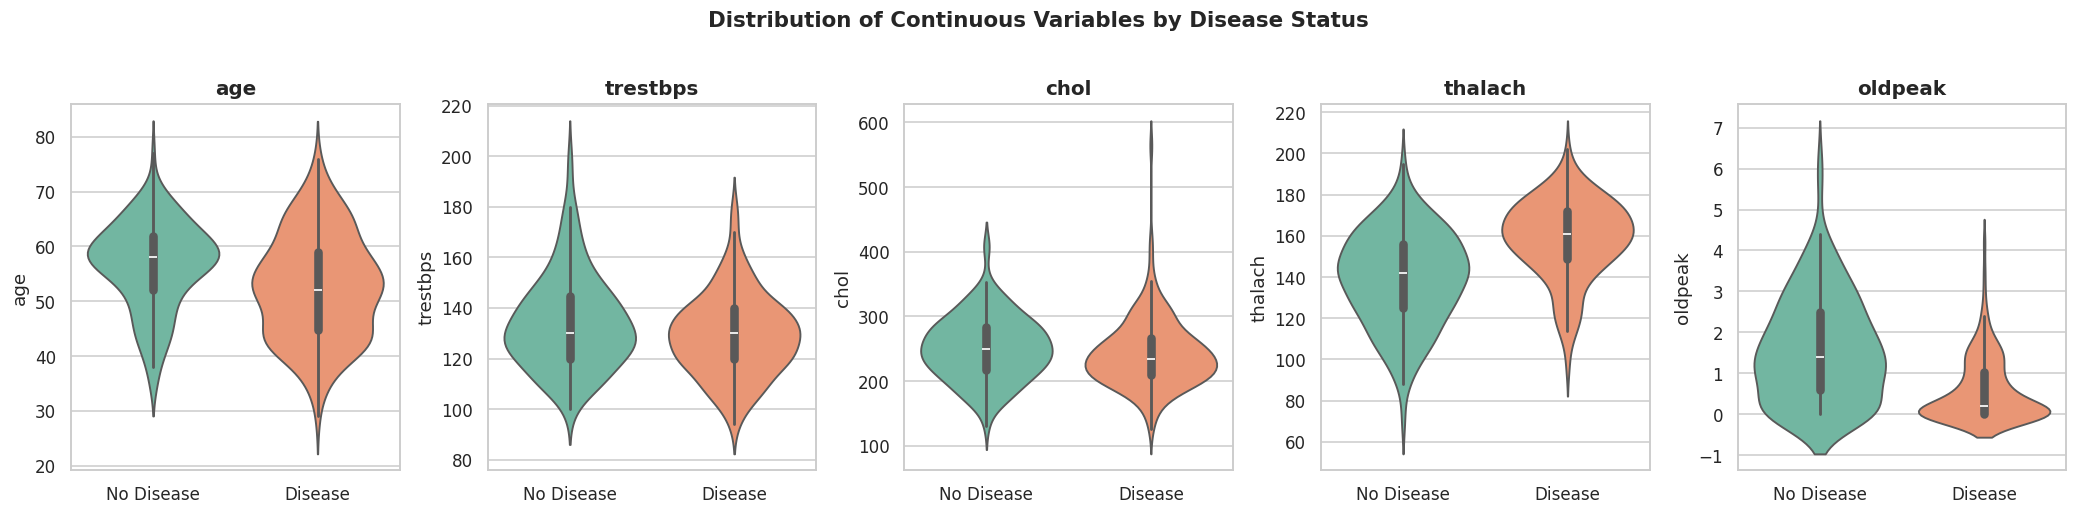

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(19, 4.5))
for ax, col in zip(axes, continuous_cols):
    sns.violinplot(data=df_clean, x='target', y=col, ax=ax, palette="Set2", hue='target', legend=False)
    ax.set_title(col)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['No Disease', 'Disease'])
    ax.set_xlabel('')
fig.suptitle('Distribution of Continuous Variables by Disease Status', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


`thalach` (max heart rate) is visibly higher in the `target = 1` group, while `oldpeak` (ST depression) is visibly higher in the `target = 0` group. Both differences are clear from the violin shapes (see the coding caution in 7.3).

### 7.5 Categorical Variables vs. Target — Grouped Bar Charts

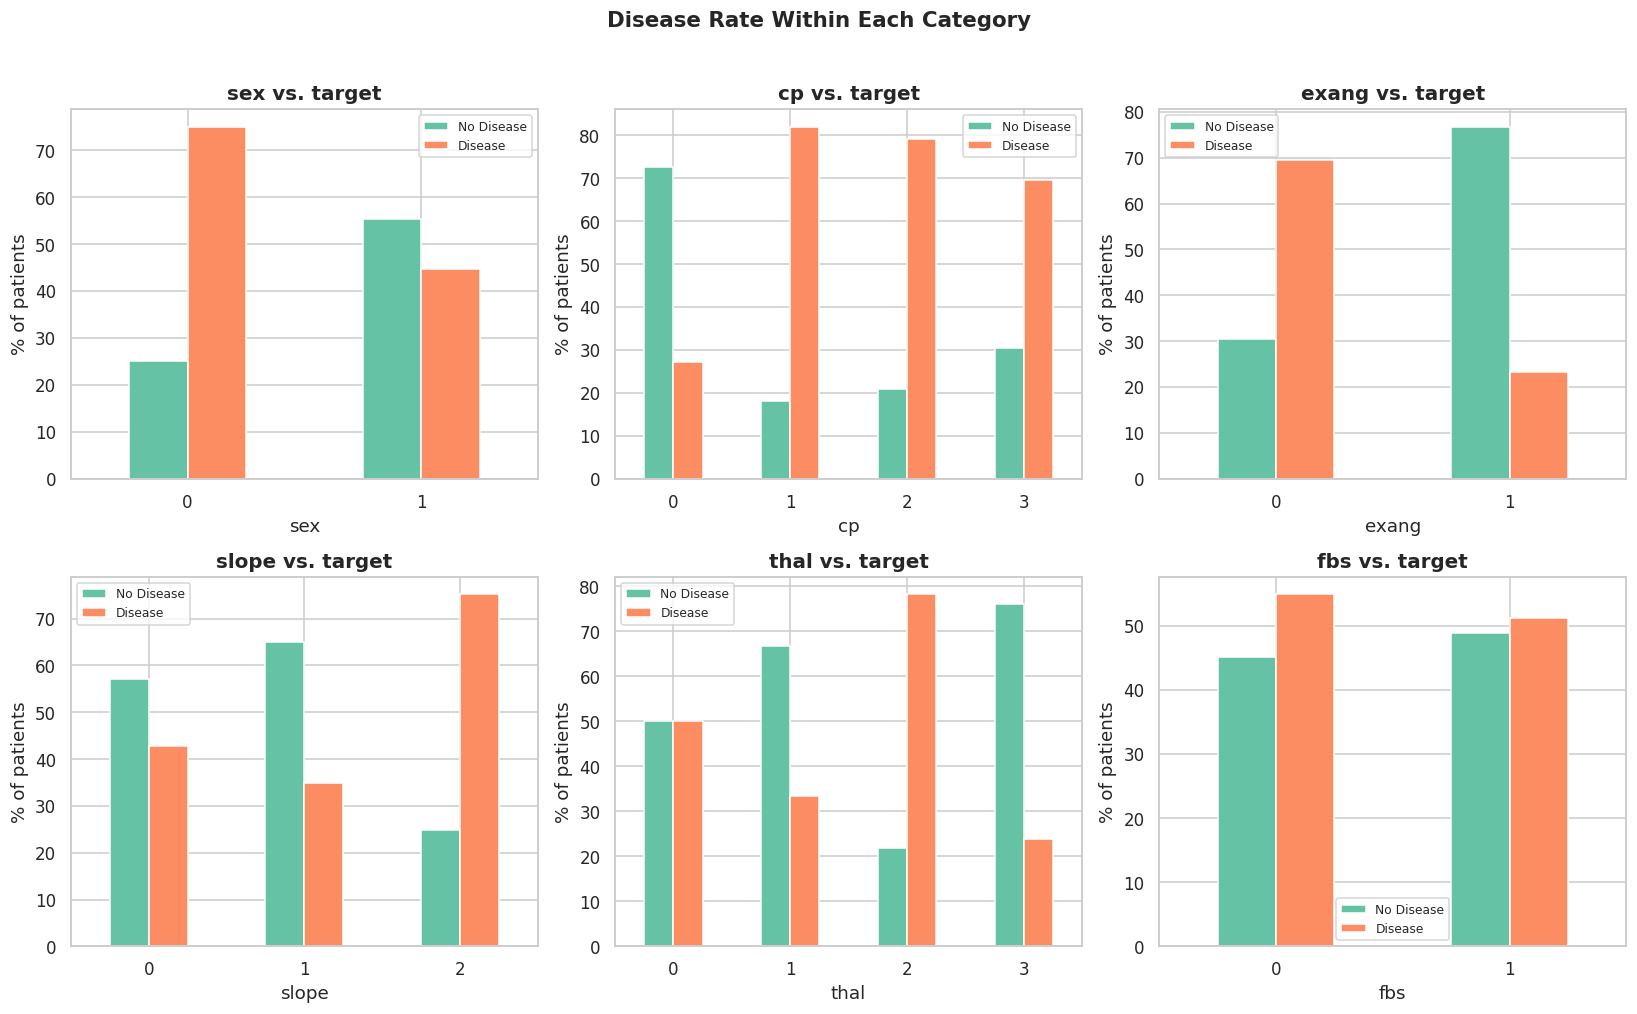

In [15]:
cat_subset = ['sex', 'cp', 'exang', 'slope', 'thal', 'fbs']
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, col in zip(axes, cat_subset):
    ct = pd.crosstab(df_clean[col], df_clean['target'], normalize='index') * 100
    ct.plot(kind='bar', stacked=False, ax=ax, color=sns.color_palette("Set2")[:2], edgecolor='white')
    ax.set_title(f'{col} vs. target')
    ax.set_ylabel('% of patients')
    ax.set_xlabel(col)
    ax.legend(['No Disease', 'Disease'], fontsize=8)
    ax.tick_params(axis='x', rotation=0)

fig.suptitle('Disease Rate Within Each Category', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


Disease rates differ sharply across categories. Typical angina (`cp = 0`) has by far the lowest disease rate (~ 27%) versus ~ 70–82% for the other chest pain types. For `thal`, category 2 has the highest rate (~ 78%) while category 3 has the lowest (~ 24%). Patients **without** exercise-induced angina (`exang = 0`) are far more often diseased (~ 69%) than those with it (~ 23%) — a counter-intuitive pattern worth verifying against the codebook/source before interpreting clinically.

### 7.6 Age vs. Max Heart Rate — Scatter Colored by Target

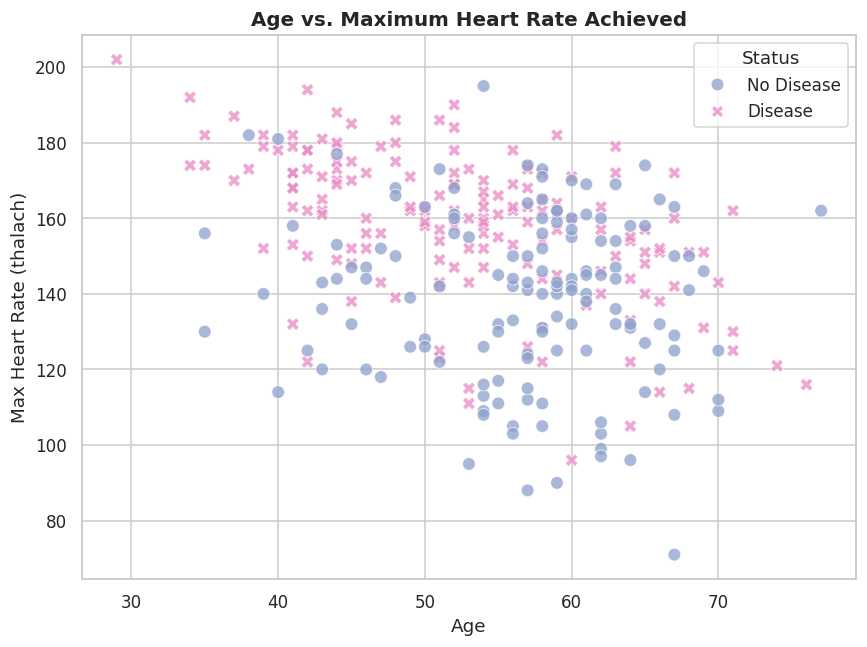

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
scatter = sns.scatterplot(data=df_clean, x='age', y='thalach', hue='target', style='target',
                           palette={0: sns.color_palette("Set2")[2], 1: sns.color_palette("Set2")[3]},
                           s=70, alpha=0.75, ax=ax, edgecolor='white', linewidth=0.6)
ax.set_title('Age vs. Maximum Heart Rate Achieved')
ax.set_xlabel('Age')
ax.set_ylabel('Max Heart Rate (thalach)')
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ['No Disease', 'Disease'], title='Status')
plt.tight_layout()
plt.show()


There's a visible downward trend (older patients tend to achieve lower max heart rates), and disease-positive points cluster toward higher `thalach` for a given age — consistent with the violin plot finding above.

### 7.7 Cholesterol & Blood Pressure — Joint Distribution

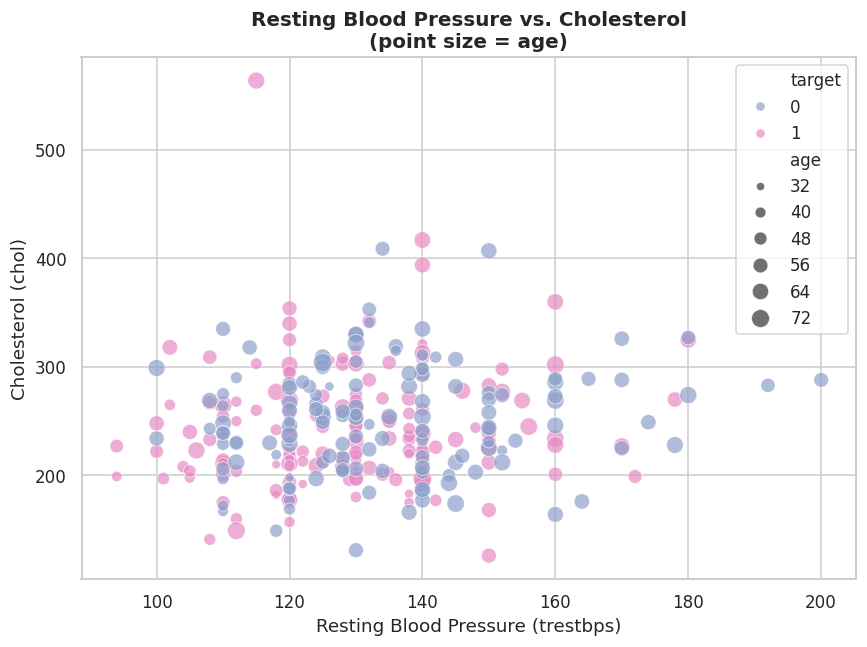

In [17]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=df_clean, x='trestbps', y='chol', hue='target', size='age', sizes=(20, 150),
                 palette={0: sns.color_palette("Set2")[2], 1: sns.color_palette("Set2")[3]},
                 alpha=0.7, ax=ax, edgecolor='white', linewidth=0.5)
ax.set_title('Resting Blood Pressure vs. Cholesterol\n(point size = age)')
ax.set_xlabel('Resting Blood Pressure (trestbps)')
ax.set_ylabel('Cholesterol (chol)')
plt.tight_layout()
plt.show()


No strong linear relationship between `trestbps` and `chol` themselves — the two risk factors appear to vary largely independently of one another in this cohort.

### 7.8 Full Pairwise Relationships — Pair Plot (Continuous Variables)

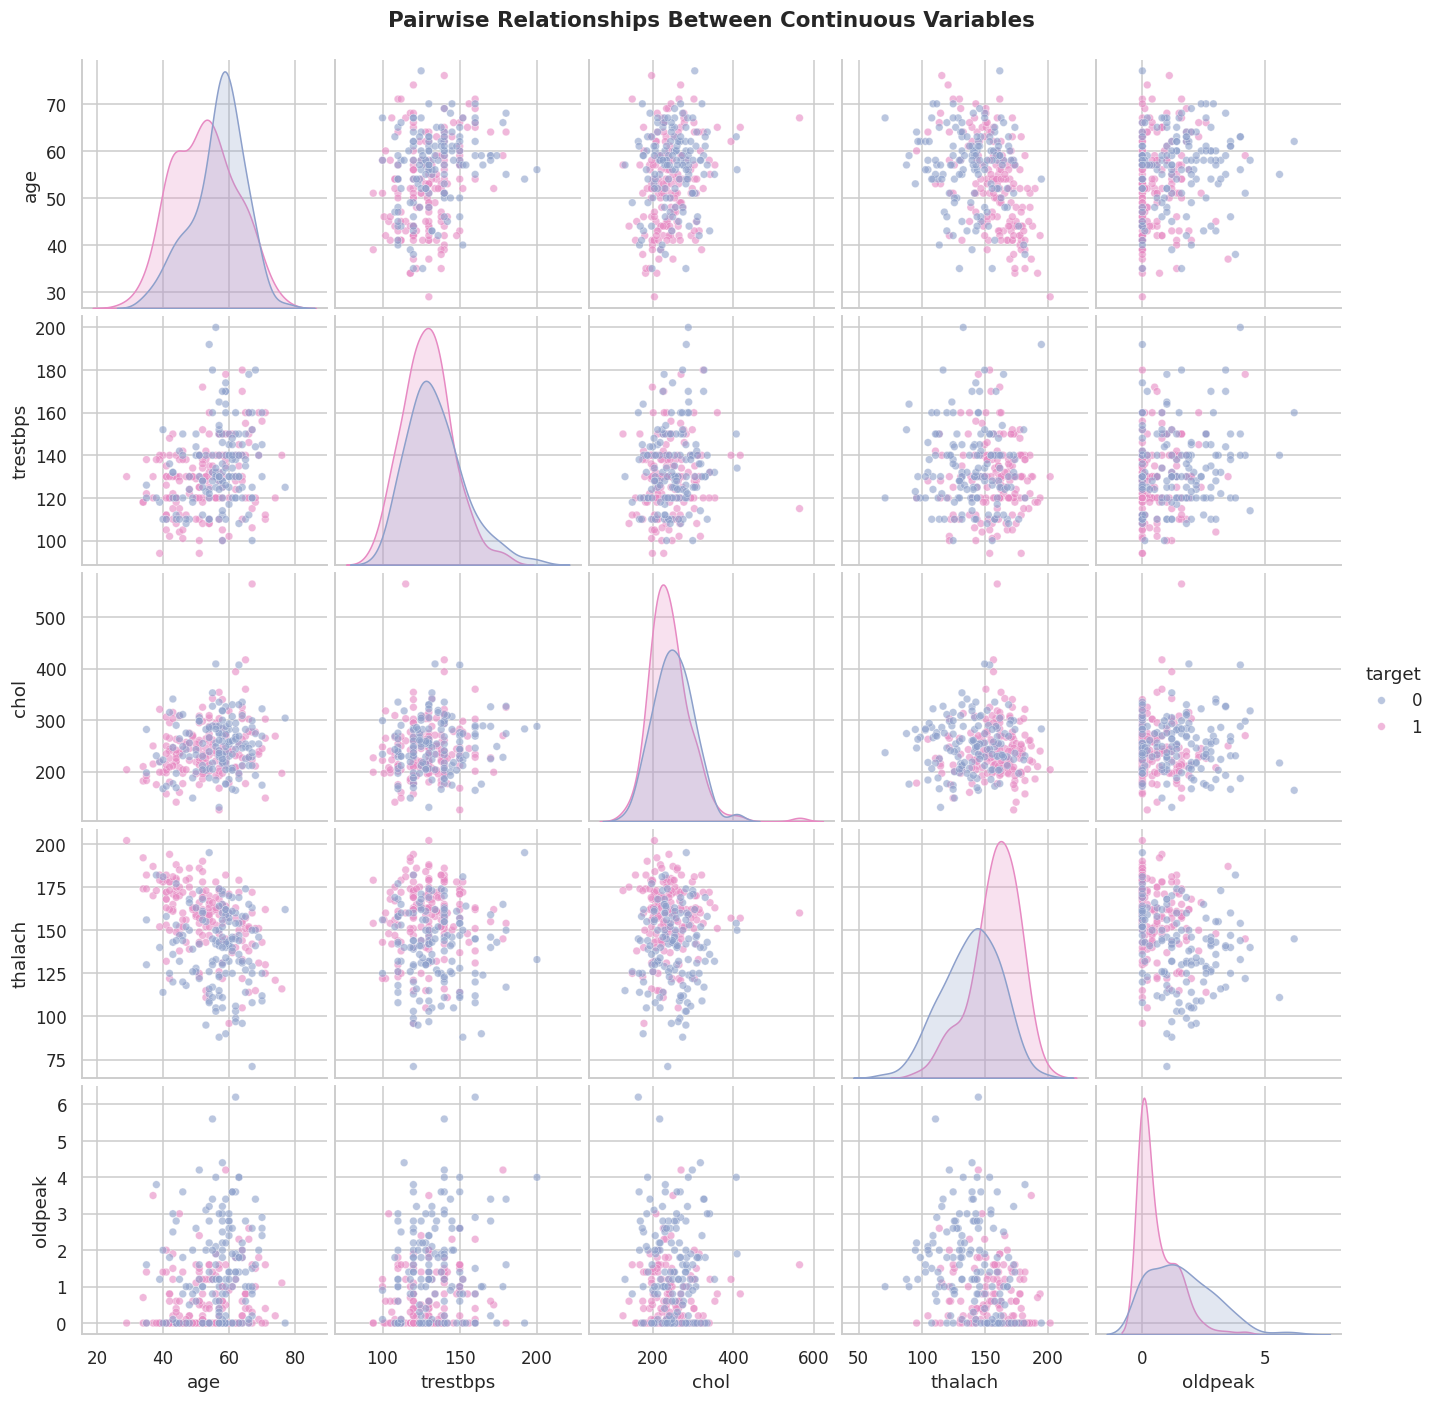

In [18]:
pair_grid = sns.pairplot(df_clean, vars=continuous_cols, hue='target',
                          palette={0: sns.color_palette("Set2")[2], 1: sns.color_palette("Set2")[3]},
                          diag_kind='kde', plot_kws={'alpha': 0.6, 's': 25, 'edgecolor': 'white', 'linewidth': 0.3})
pair_grid.fig.suptitle('Pairwise Relationships Between Continuous Variables', y=1.02, fontsize=14, fontweight='bold')
plt.show()


The diagonal KDEs summarize each variable's distribution split by disease status, echoing the violin-plot patterns; the off-diagonal scatter panels confirm none of the continuous variables are strongly linearly correlated with one another (supporting the correlation heatmap).

### 7.9 Chest Pain Type × Sex — Heatmap of Disease Rate

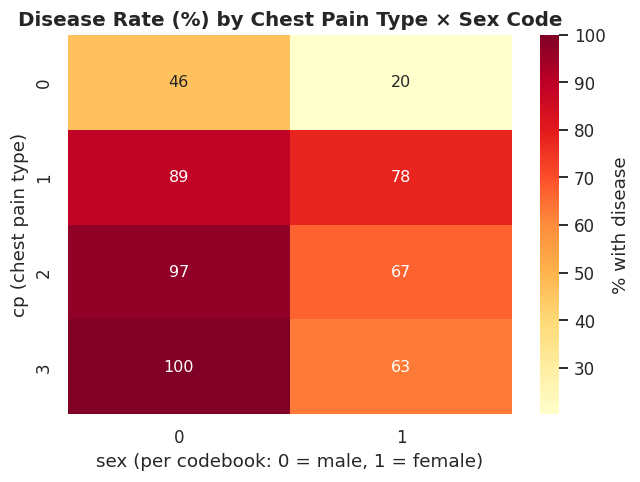

In [19]:
pivot = df_clean.pivot_table(index='cp', columns='sex', values='target', aggfunc='mean') * 100
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd', cbar_kws={'label': '% with disease'}, ax=ax)
ax.set_title('Disease Rate (%) by Chest Pain Type × Sex Code')
ax.set_xlabel('sex (per codebook: 0 = male, 1 = female)')
ax.set_ylabel('cp (chest pain type)')
plt.tight_layout()
plt.show()


This cross-tabulation shows how disease prevalence shifts across the combination of chest pain type and the `sex` code — useful for spotting subgroup patterns that a single-variable view would miss.

### 7.10 ST Depression (`oldpeak`) by Slope Category

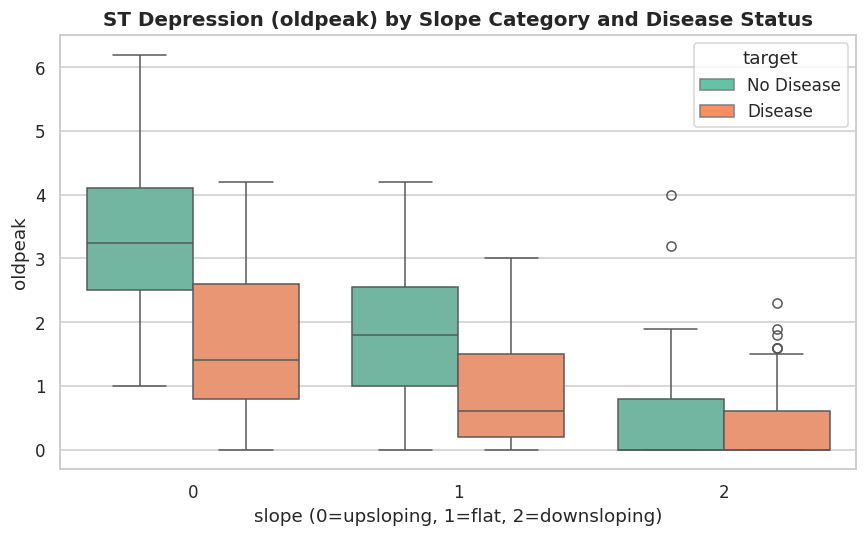

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df_clean, x='slope', y='oldpeak', hue='target', palette="Set2", ax=ax)
ax.set_title('ST Depression (oldpeak) by Slope Category and Disease Status')
ax.set_xlabel('slope (0=upsloping, 1=flat, 2=downsloping)')
ax.set_ylabel('oldpeak')
from matplotlib.patches import Patch
pal = sns.color_palette("Set2")[:2]
ax.legend(handles=[Patch(facecolor=pal[0], edgecolor='gray', label='No Disease'),
                   Patch(facecolor=pal[1], edgecolor='gray', label='Disease')], title='target')
plt.tight_layout()
plt.show()


`oldpeak` is highest for `slope = 0` (median ≈ 2.6) and lowest for `slope = 2` (median ≈ 0), and within every slope category the **disease-negative** group has the higher `oldpeak`. This matches the violin plots in 7.4 (higher `oldpeak` in the no-disease group) and, like the `exang` pattern above, runs opposite to the usual clinical expectation, which is a reason to double-check how the target is coded in the source data.

## 8. Summary

| Step | Result |
|---|---|
| Missing values | None found (standard or disguised) |
| Non-numeric characters | None — all columns are clean numeric |
| Duplicate rows | 1 found and removed |
| Suspicious values | `ca = 4` (4 rows after dedup) and `thal = 0` (2 rows): 6 rows flagged as likely missing-value codes, not removed |
| Outliers | Present in `trestbps` (9), `chol` (5), `oldpeak` (5), `thalach` (1) but judged clinically plausible; kept, with capped versions available for visualization only |
| Class balance | Target is reasonably balanced (~54% disease / ~46% no disease) |

**Key visual takeaways (as coded in the file):**
- `cp` (chest pain type), `thalach` (max heart rate), and `slope` are positively associated with `target = 1`; `exang`, `oldpeak`, `ca`, and `thal` are negatively associated.
- Several of these directions are opposite to clinical expectation if `target = 1` means "disease", so the target coding should be verified against the original source.
- Continuous variables are largely uncorrelated with each other, so each carries fairly independent information for a future predictive model.
- Outlier and invalid-value decisions were made from each column's own distribution/range, never from the target.